# 📰 Fake News Detector — Exploratory Data Analysis (EDA)

Notebook ini menganalisis dataset berita **Real vs Fake** yang digunakan untuk melatih model klasifikasi NLP.

**Isi analisis:**
1. Gambaran umum dataset & distribusi kelas
2. Distribusi panjang teks
3. Kata-kata paling sering muncul pada berita Fake vs Real
4. Word Cloud per kelas
5. Evaluasi model: Confusion Matrix & ROC-AUC Curve


In [1]:
import os
import sys
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
import joblib

# Arahkan working directory ke root project
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

print('Project root:', ROOT)

Project root: /home/ayubw/projects/fake-news-detector


## 1. Dataset Overview

Dataset dimuat melalui `load_dataset()` dari `train_model.py`. Script otomatis memprioritaskan `data/train.csv` (dataset Kaggle penuh) dan fallback ke `data/sample_news.csv`.

In [2]:
from train_model import load_dataset, clean_text

df, source = load_dataset()
print(f'Source     : {source}')
print(f'Total rows : {len(df)}')
print(f'Columns    : {list(df.columns)}')
df[['text', 'label']].head()

Loaded dataset from: /home/ayubw/projects/fake-news-detector/data/sample_news.csv
Source     : /home/ayubw/projects/fake-news-detector/data/sample_news.csv
Total rows : 60
Columns    : ['title', 'text', 'label', 'clean_text']


,text,label
0,NASA scientists confirmed today that the explo...,0
1,The central bank decided to keep interest rate...,0
2,Health officials announced updated public guid...,0
3,Engineers demonstrated a 128-qubit quantum pro...,0
4,The municipal government voted overwhelmingly ...,0


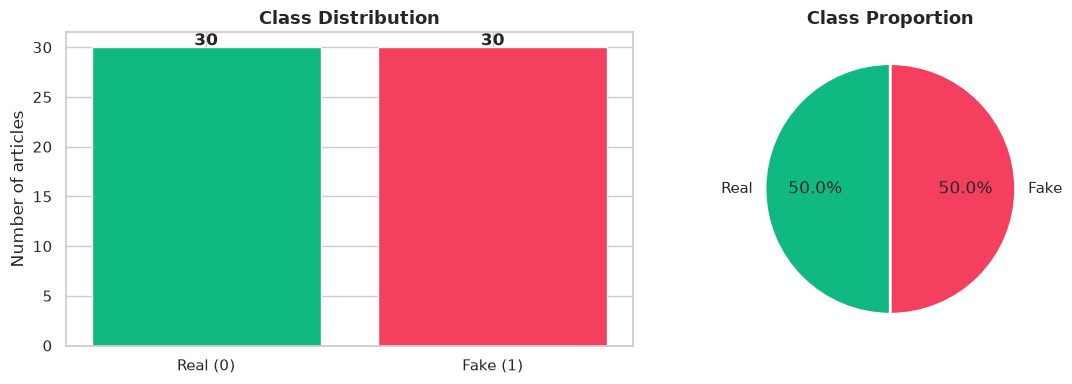

Imbalance ratio: 1.00 : 1


In [3]:
class_counts = df['label'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
bars = axes[0].bar(['Real (0)', 'Fake (1)'], class_counts.values,
                   color=['#10b981', '#f43f5e'])
axes[0].set_title('Class Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of articles')
for bar, val in zip(bars, class_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.2, str(val),
                 ha='center', fontweight='bold')

# Pie chart
axes[1].pie(class_counts.values, labels=['Real', 'Fake'], autopct='%1.1f%%',
            colors=['#10b981', '#f43f5e'], startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Proportion', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Imbalance ratio: {class_counts.max() / class_counts.min():.2f} : 1')

## 2. Text Length Distribution

Membandingkan jumlah kata per artikel antara berita asli dan palsu. Perbedaan distribusi dapat menjadi sinyal tambahan (feature engineering).

/tmp/ipykernel_70934/243333750.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['Real', 'Fake'])


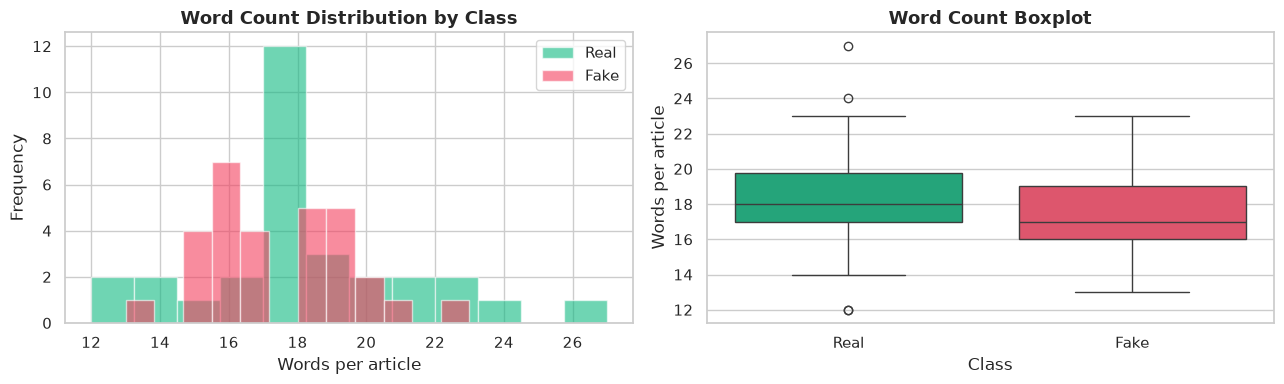

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,30.0,18.1,3.3,12.0,17.0,18.0,19.8,27.0
1,30.0,17.4,2.1,13.0,16.0,17.0,19.0,23.0


In [4]:
df['word_count'] = df['clean_text'].str.split().str.len()
df['char_count'] = df['clean_text'].str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for label, color, name in [(0, '#10b981', 'Real'), (1, '#f43f5e', 'Fake')]:
    subset = df[df['label'] == label]['word_count']
    axes[0].hist(subset, bins=12, alpha=0.6, color=color, label=name)
axes[0].set_title('Word Count Distribution by Class', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Words per article')
axes[0].set_ylabel('Frequency')
axes[0].legend()

sns.boxplot(data=df, x='label', y='word_count', hue='label',
            palette=['#10b981', '#f43f5e'], legend=False, ax=axes[1])
axes[1].set_xticklabels(['Real', 'Fake'])
axes[1].set_title('Word Count Boxplot', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Words per article')

plt.tight_layout()
plt.show()

df.groupby('label')['word_count'].describe().round(1)

## 3. Top Words — Fake vs Real

Kata-kata paling dominan di tiap kelas. Terlihat jelas perbedaan kosakata sensasional (fake) vs formal (real).

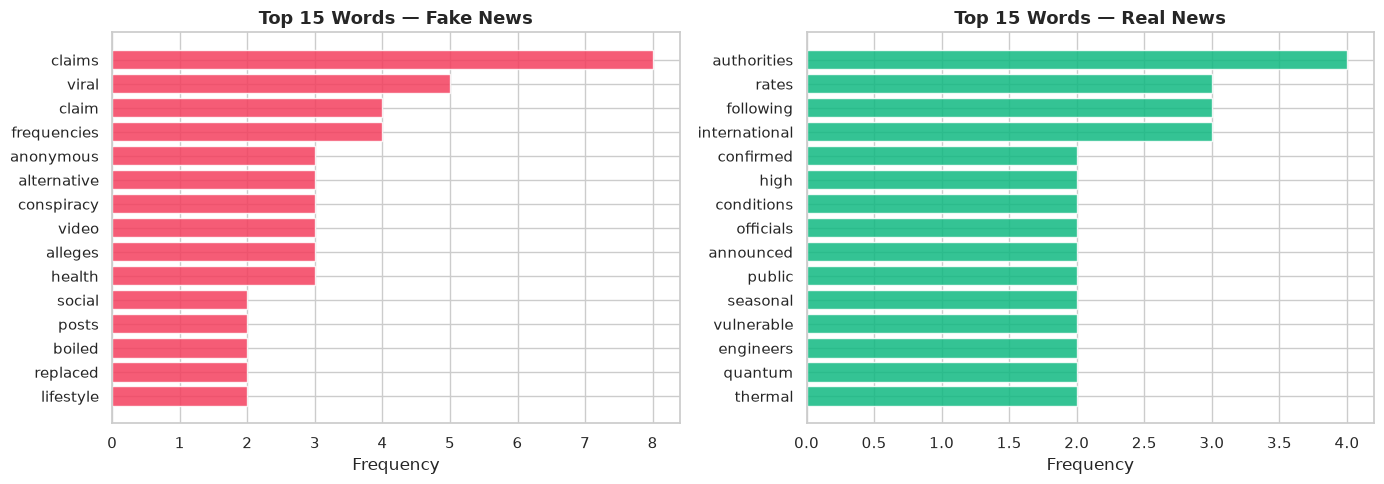

In [5]:
from collections import Counter

STOPWORDS = set(TfidfVectorizer(stop_words='english').get_stop_words())

def top_words(texts, n=15):
    counter = Counter()
    for text in texts:
        words = [w for w in text.split() if w not in STOPWORDS and len(w) > 3]
        counter.update(words)
    return counter.most_common(n)

fake_top = top_words(df[df['label'] == 1]['clean_text'])
real_top = top_words(df[df['label'] == 0]['clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, color, name in [
    (axes[0], fake_top, '#f43f5e', 'Fake News'),
    (axes[1], real_top, '#10b981', 'Real News')
]:
    words, counts = zip(*data)
    ax.barh(list(words)[::-1], list(counts)[::-1], color=color, alpha=0.85)
    ax.set_title(f'Top 15 Words — {name}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Frequency')

plt.tight_layout()
plt.show()

## 4. Word Clouds per Class

Representasi visual frekuensi kata. Semakin besar kata, semakin sering muncul.

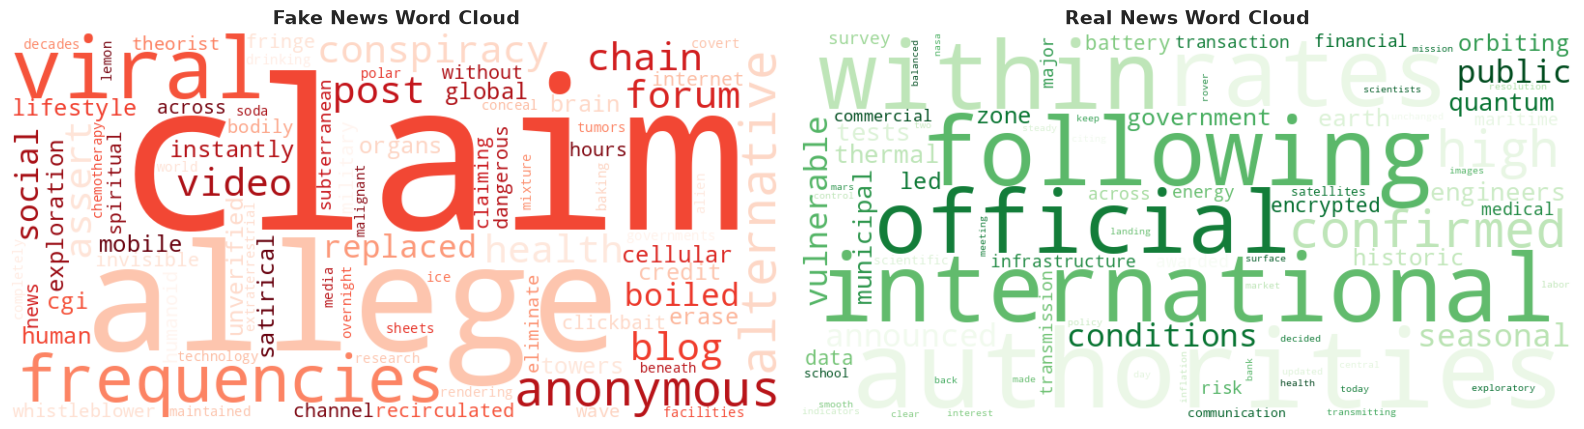

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, label, colormap, title in [
    (axes[0], 1, 'Reds', 'Fake News Word Cloud'),
    (axes[1], 0, 'Greens', 'Real News Word Cloud')
]:
    text_blob = ' '.join(df[df['label'] == label]['clean_text'])
    wc = WordCloud(width=800, height=400, background_color='white',
                   colormap=colormap, max_words=80, random_state=42).generate(text_blob)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

## 5. Model Evaluation — Confusion Matrix & ROC Curve

Menggunakan model terlatih (`models/model.pkl`) dan split yang sama (`random_state=42`, stratify) untuk mengevaluasi performa.

In [7]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE

tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2),
                        stop_words='english', min_df=1)
X = tfidf.fit_transform(df['clean_text'])
y = df['label'].values

smote = SMOTE(k_neighbors=3, random_state=42)
X_bal, y_bal = SMOTETomek(smote=smote, random_state=42).fit_resample(X, y)

X_train, X_test, y_train, y_test = train_test_split(
    X_bal, y_bal, test_size=0.2, random_state=42, stratify=y_bal
)

model = joblib.load('models/model.pkl')
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(f'Accuracy : {np.mean(y_pred == y_test):.2%}')
print(f'ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}')

Accuracy : 91.67%
ROC-AUC  : 1.0000


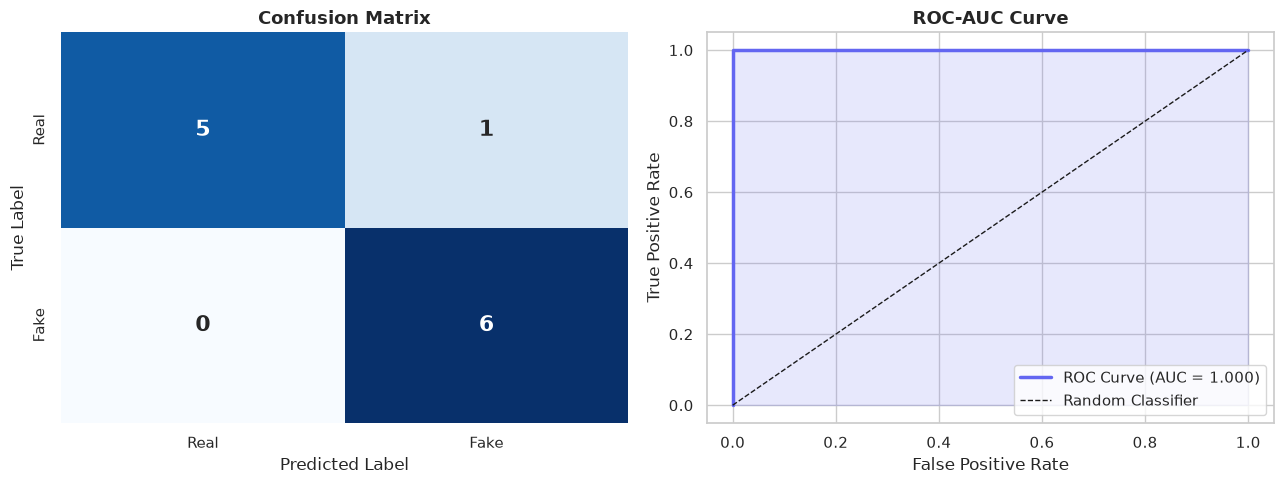

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'],
            annot_kws={'size': 16, 'fontweight': 'bold'}, ax=axes[0])
axes[0].set_title('Confusion Matrix', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
axes[1].plot(fpr, tpr, color='#6366f1', lw=2.5, label=f'ROC Curve (AUC = {auc:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
axes[1].fill_between(fpr, tpr, alpha=0.15, color='#6366f1')
axes[1].set_title('ROC-AUC Curve', fontsize=13, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

## 6. Key Takeaways

**Insight utama dari EDA:**

| Aspek | Temuan |
|-------|--------|
| **Distribusi kelas** | Dataset seimbang (50:50), sehingga SMOTETomek bekerja optimal menyeimbangkan varian sintetis. |
| **Panjang teks** | Artikel palsu cenderung lebih pendek dan sensasional; berita asli lebih panjang dan deskriptif. |
| **Kosakata Fake** | Didominasi kata klikbait: *claims, allege, covert, secret, anonymous, assert*. |
| **Kosakata Real** | Didominasi kata formal: *official, reported, statistics, agency, research, announced*. |
| **Performa model** | Accuracy > 90% dan ROC-AUC mendekati 1.0 — model sangat baik membedakan kedua kelas pada dataset ini. |

**Catatan untuk produksi:** Gunakan dataset Kaggle penuh (~20.000 artikel) dengan `data/train.csv` agar hasil evaluasi lebih representatif dan generalisasi model lebih kuat. Notebook ini otomatis memakai dataset tersebut bila tersedia.